# Разведочный анализ данных

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pyproj import Transformer

Загрузка данных.

In [3]:
df = pd.read_parquet('../../data/processed/features_table.parquet')

print(f"Всего ячеек: {len(df)}")
print(f"Ячеек с месторождениями (is_deposit=1): {df['is_deposit'].sum()}")
print(f"Доля месторождений: {df['is_deposit'].mean():.4%}")

display(df.head())

Всего ячеек: 35694
Ячеек с месторождениями (is_deposit=1): 9
Доля месторождений: 0.0252%


,x,y,latitude,longitude,is_deposit,deposit_name,fold_id,elevation,magnetic,gravity
0,459500.0,6485500.0,58.508188,92.304945,0,,3,122.0,-176.118240,62.864227
1,459500.0,6486500.0,58.517168,92.304768,0,,3,114.0,-180.356430,63.677711
2,459500.0,6487500.0,58.526149,92.304590,0,,1,105.0,-184.596954,64.498230
3,459500.0,6488500.0,58.535129,92.304412,0,,1,96.0,-188.797043,65.087418
4,459500.0,6489500.0,58.544110,92.304234,0,,1,92.0,-192.825455,64.723465


Проверка на пропуски.

In [4]:
print(df[['elevation', 'magnetic', 'gravity']].isnull().sum())

elevation    0
magnetic     0
gravity      0
dtype: int64


Визуализация распределений: месторождения (1) и неизвестные (0).

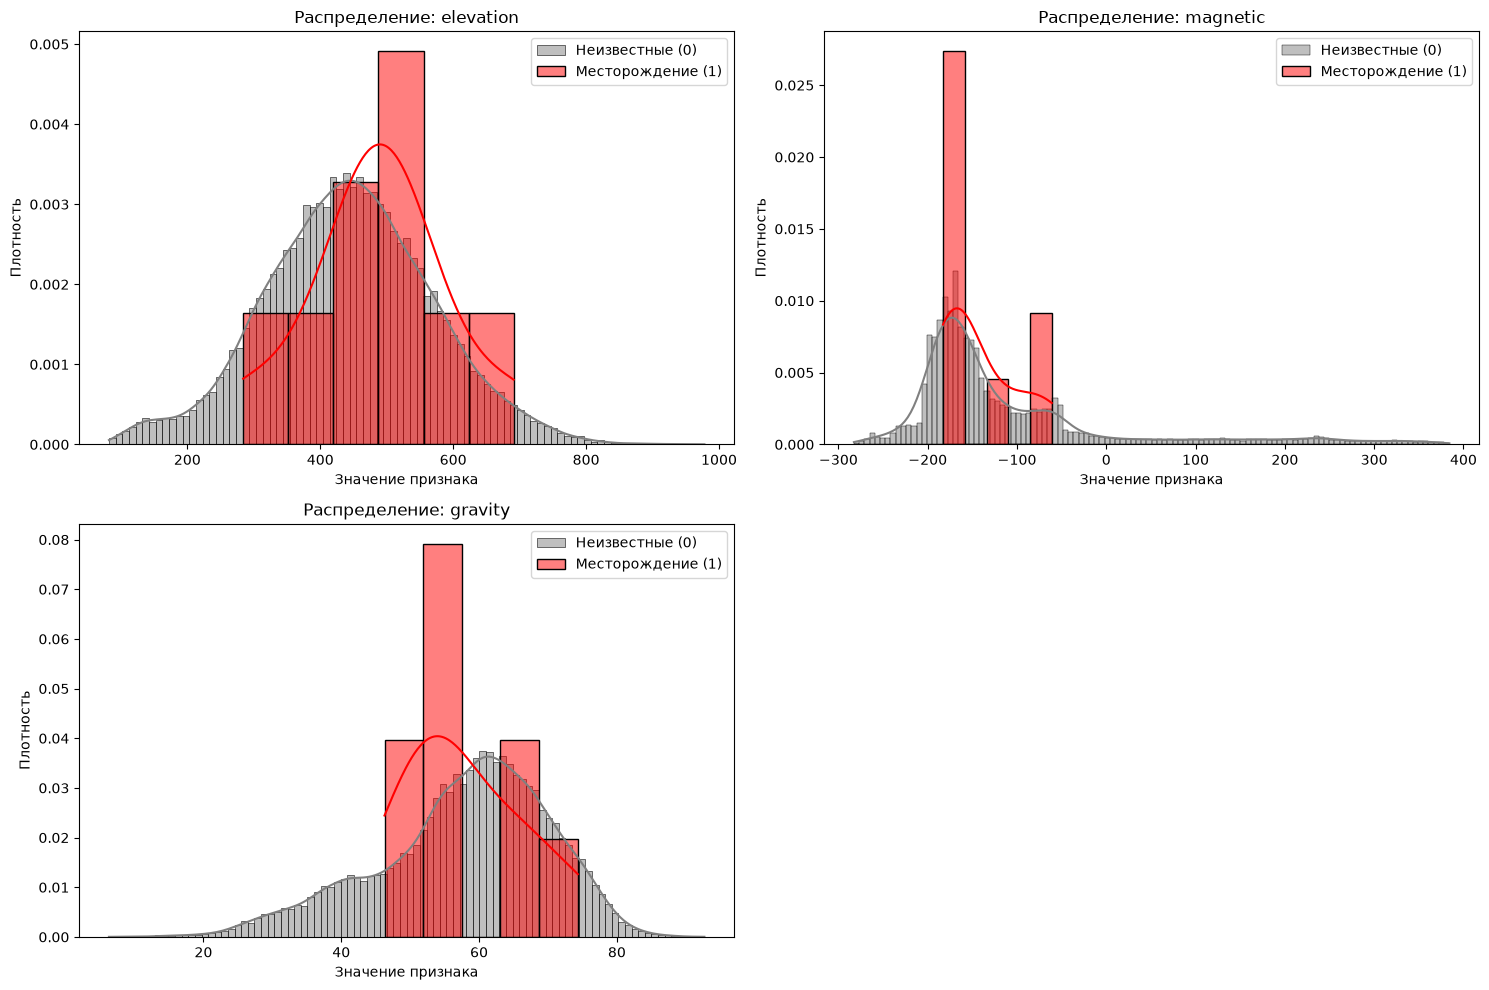

In [5]:
features = ['elevation', 'magnetic', 'gravity']

plt.figure(figsize=(15, 10))
for i, feature in enumerate(features, 1):
    plt.subplot(2, 2, i)
    
    sns.histplot(df[df['is_deposit'] == 0][feature], color='gray', label='Неизвестные (0)', kde=True, stat='density')
    sns.histplot(df[df['is_deposit'] == 1][feature], color='red', label='Месторождение (1)', kde=True, stat='density')
    
    plt.title(f'Распределение: {feature}')
    plt.xlabel('Значение признака')
    plt.ylabel('Плотность')
    plt.legend()

plt.tight_layout()
plt.show()

**elevation** (высота над уровнем моря):  
* Положительные ячейки в основном находятся в диапазоне примерно 300–700 м.  
* Значительная часть распределения положительных ячеек пересекается с распределением неизвестных.  
* Явного разделения по высоте нет.  

Интерпретация: рельеф может косвенно отражать эрозионную расчленённость, положение долин и водоразделов, а также обнажённость пород. Но сама по себе высота не является прямым индикатором золотого оруденения.  

**magnetic** (магнитное поле):  
* У положительных ячеек заметны концентрации примерно около −180 и −80 нТл.  
* Распределение неизвестных ячеек существенно шире, включая положительные значения.  
* Есть потенциальные различия между группами, но выборка из 11 объектов слишком мала для уверенных выводов.  

Интерпретация: магнитные аномалии могут отражать изменения состава и структуры пород, контакты геологических тел и зоны изменения магнитных минералов. Некоторые из этих структур могут быть связаны с оруденением, но связь не универсальна.  

**gravity** (гравитационное поле):  
* Положительные ячейки сосредоточены преимущественно около 47–70 в используемой шкале.  
* Есть пересечение с неизвестными ячейками.  
* На графике заметен высокий пик, но при 11 наблюдениях он может определяться всего несколькими значениями и выбранными границами интервалов.  

Интерпретация: гравитационные аномалии связаны с различиями плотности пород и глубинным строением. Они могут помогать распознавать крупные структуры, но пространственное разрешение гравитационного слоя может быть существенно грубее сетки 1 км.

Корреляция признаков.

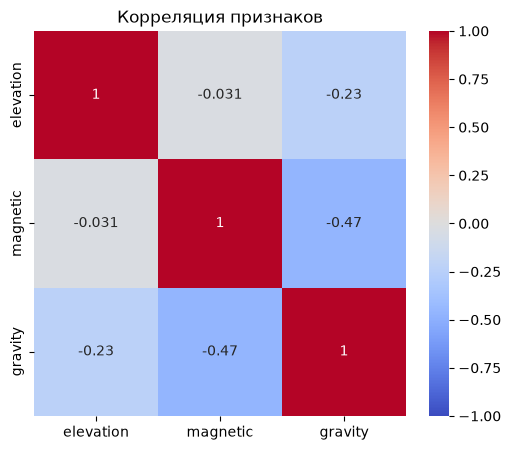

,elevation,magnetic,gravity
elevation,1.000000,-0.031085,-0.228413
magnetic,-0.031085,1.000000,-0.467039
gravity,-0.228413,-0.467039,1.000000


In [6]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[features].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляция признаков')
plt.show()

display(df[features].corr())

Не выявлена сильная линейная зависимость между признаками.

Сетка (полнота и регулярность) и согласованность координат.

In [18]:
xs = np.sort(df["x"].unique())
ys = np.sort(df["y"].unique())

assert np.all(np.diff(xs) == 1000), "Нерегулярный шаг X"
assert np.all(np.diff(ys) == 1000), "Нерегулярный шаг Y"
assert not df.duplicated(["x", "y"]).any(), "Дубликаты ячеек"

expected = pd.MultiIndex.from_product(
    [xs, ys],
    names=["x", "y"]
)
actual = pd.MultiIndex.from_frame(df[["x", "y"]])

missing_cells = expected.difference(actual)

print("Ожидаемых ячеек:", len(expected))
print("Фактических ячеек:", len(actual))
print("Отсутствующих ячеек:", len(missing_cells))

print("\nДоля пропусков:")
print(df[features + ["fold_id", "is_deposit"]].isna().mean())

print("\nЧисло уникальных значений fold_id:")
print(df["fold_id"].nunique())

print("\nРазмеры фолдов:")
print(df.groupby("fold_id").size().sort_index())


Ожидаемых ячеек: 37288
Фактических ячеек: 35694
Отсутствующих ячеек: 1594

Доля пропусков:
elevation     0.0
magnetic      0.0
gravity       0.0
fold_id       0.0
is_deposit    0.0
dtype: float64

Число уникальных значений fold_id:
5

Размеры фолдов:
fold_id
0     4874
1     7273
2     3359
3    17250
4     2938
dtype: int64


In [17]:
transformer = Transformer.from_crs(
    "EPSG:32646",
    "EPSG:4326",
    always_xy=True
)

lon_calc, lat_calc = transformer.transform(
    df["x"].to_numpy(),
    df["y"].to_numpy()
)

print(
    "max |Δlat|:",
    np.abs(lat_calc - df["latitude"].to_numpy()).max()
)
print(
    "max |Δlon|:",
    np.abs(lon_calc - df["longitude"].to_numpy()).max()
)

dep = df.loc[df["is_deposit"].eq(1)].copy()

print("Депозитов в таблице:", len(dep))
print("Уникальных названий:", dep["deposit_name"].nunique())
print("Пустых названий:", dep["deposit_name"].isna().sum())
print(
    dep[["deposit_name", "x", "y", "latitude", "longitude", "fold_id"]]
    .sort_values("deposit_name")
    .to_string(index=False)
)

max |Δlat|: 4.999995439902705e-08
max |Δlon|: 4.9995364292954037e-08
Депозитов в таблице: 9
Уникальных названий: 9
Пустых названий: 0
         deposit_name        x         y  latitude  longitude  fold_id
          Blagodatnoe 497500.0 6658500.0 60.063644  92.955093        1
     Eldorado deposit 516500.0 6657500.0 60.054341  93.296304        3
       Gerfed deposit 571500.0 6507500.0 58.701747  94.233901        3
  Konduyak Au deposit 561500.0 6566500.0 59.233052  94.077775        0
Panimbinskoye deposit 526500.0 6602500.0 59.559959  93.468890        4
 Sovetskoe Au deposit 490500.0 6688500.0 60.332910  92.827949        2
       Uderey deposit 604500.0 6541500.0 59.000232  94.819056        3
 Vasilevskoye deposit 577500.0 6506500.0 58.691735  94.337070        3
       Veduga deposit 518500.0 6584500.0 59.398753  93.325782        1


Анализ фолдов.

In [21]:
fold_report = (
    df.groupby("fold_id")
      .agg(
          cells=("is_deposit", "size"),
          deposits=("is_deposit", "sum"),
          unlabeled=("is_deposit", lambda s: (s == 0).sum()),
      )
      .sort_index()
)

total_deposits = int(df["is_deposit"].sum())

fold_report["train_deposits"] = (
    total_deposits - fold_report["deposits"]
)

display(fold_report)

,cells,deposits,unlabeled,train_deposits
fold_id,,,,
0,4874,1,4873,8
1,7273,2,7271,7
2,3359,1,3358,8
3,17250,4,17246,5
4,2938,1,2937,8


fold_id
3    17250
1     7273
0     4874
2     3359
4     2938
Name: count, dtype: int64

Депозитов на фолд:
 fold_id
3    4
1    2
2    1
4    1
0    1
Name: count, dtype: int64


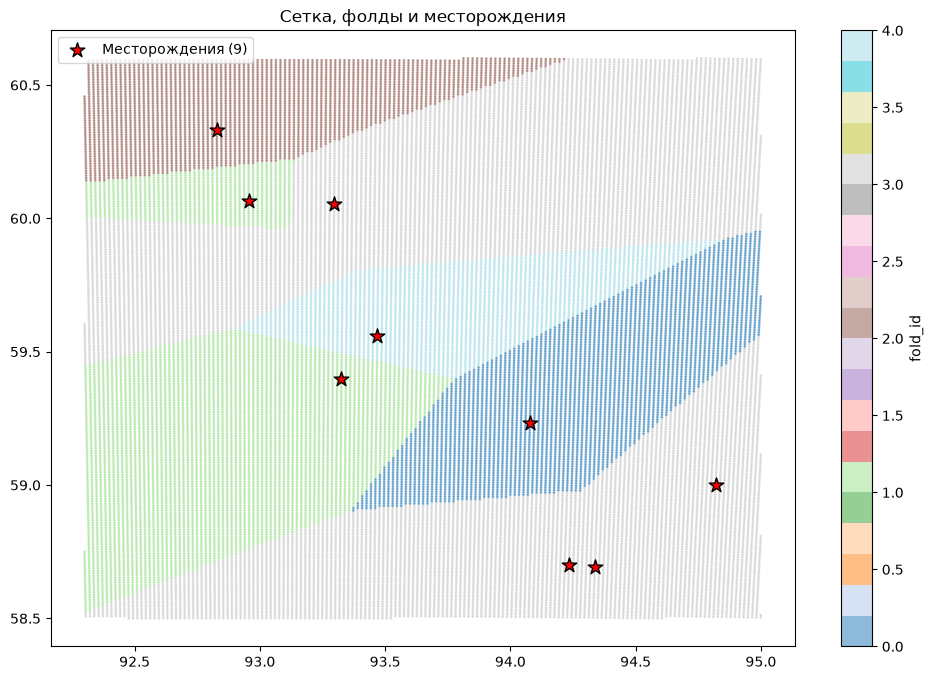

In [20]:
print(df['fold_id'].value_counts())
print("\nДепозитов на фолд:\n", dep['fold_id'].value_counts())

plt.figure(figsize=(12, 8))
sc = plt.scatter(df['longitude'], df['latitude'], c=df['fold_id'],
                 cmap='tab20', s=1, alpha=0.5)
plt.scatter(dep['longitude'], dep['latitude'], c='red', s=120, marker='*',
            edgecolors='black', label=f'Месторождения ({len(dep)})', zorder=3)
plt.colorbar(sc, label='fold_id')
plt.legend(); plt.title('Сетка, фолды и месторождения'); plt.show()

ECDF и сводная таблицуа

elevation                                              magnetic  \
               count median        mean         std    min    max    count   
is_deposit                                                                   
0              35685  443.0  443.601962  126.214812   82.0  978.0    35685   
1                  9  489.0  487.888889  109.718326  284.0  691.0        9   

                                                                        \
                median        mean         std         min         max   
is_deposit                                                               
0          -154.087708 -110.041167  122.263568 -282.633392  384.205627   
1          -163.312607 -142.381416   43.695705 -182.796051  -61.041298   

           gravity                                                         
             count     median       mean        std        min        max  
is_deposit                                                                 
0            35685  59.544735  57.815588  12.425315   6.285794  92.698593  
1                9  57.012203  57.973340   8.856126  46.276077  74.327545

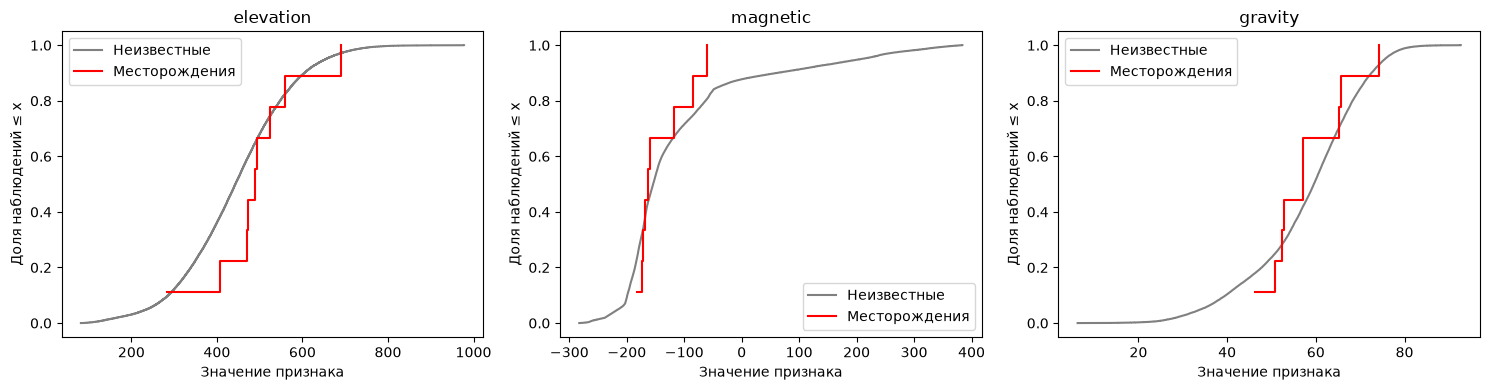

In [22]:
summary = (
    df.groupby("is_deposit")[features]
      .agg(["count", "median", "mean", "std", "min", "max"])
)

display(summary)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, features):
    for label, name, color in [
        (0, "Неизвестные", "gray"),
        (1, "Месторождения", "red"),
    ]:
        values = np.sort(
            df.loc[df["is_deposit"].eq(label), feature]
              .dropna()
              .to_numpy()
        )

        if len(values) == 0:
            continue

        ecdf = np.arange(1, len(values) + 1) / len(values)
        ax.step(values, ecdf, where="post", label=name, color=color)

    ax.set_title(feature)
    ax.set_xlabel("Значение признака")
    ax.set_ylabel("Доля наблюдений ≤ x")
    ax.legend()

plt.tight_layout()
plt.show()